# Additional Sprint 1 EDA

This notebook extends the audit with numeric distributions and correlations, missingness by class and region, and age comparisons within region and extraction class. The findings and limitations are documented in [the report](../reports/sprint1_additional_eda.md).

Install the locked project environment with `uv sync`. Raw inputs remain local under `data/raw/`. Run all cells from the project root or `notebooks/`; the shared module resolves paths from its installed location.

In [1]:
import json

import pandas as pd
from IPython.display import Image, display

from team_wtm.additional_eda import DEFAULT_OUTPUT, run_analysis

# Reuses the shared cleaner; writes aggregate summaries and figures only.
results = run_analysis()
display(pd.Series(results['counts'], name='Rows'))

all_rows             59400
usable_age           38682
unknown_year         20709
invalid_known_age        9
elevation_zero       20438
Name: Rows, dtype: int64

## Numeric features

Age uses the recording year. Unknown construction years and invalid ages do not enter the age calculations. Population zeros follow the shared unknown-value convention. Amount and elevation zeros remain observed values. IDs, numeric category codes and the target are excluded from numeric correlation.

Density histograms use shared bins and separate within-class normalization. Population and amount use a signed log1p display transformation. Boxplots use original values on a symmetric log axis for those two fields. Outlier markers are omitted from the boxplots, while all values remain in the summaries and histograms.

,feature,status,class_n,valid_n,missing_n,zero_n,negative_n,min,p01,p25,median,p75,p99,max
0,pump_age,functional,32259,21700,10559,413,0,0.0,0.0,3.0,9.0,18.0,43.00,53.0
1,pump_age,functional needs repair,4317,2528,1789,11,0,0.0,1.0,6.0,14.0,27.0,45.00,53.0
2,pump_age,non functional,22824,14454,8370,164,0,0.0,0.0,7.0,18.0,31.0,49.47,53.0
3,population,functional,32259,20985,11274,0,0,1.0,1.0,45.0,150.0,316.0,2600.00,30500.0
4,population,functional needs repair,4317,2542,1775,0,0,1.0,1.0,60.0,200.0,397.5,1711.80,15300.0
5,population,non functional,22824,14492,8332,0,0,1.0,1.0,1.0,150.0,320.0,2202.70,9865.0
6,amount_tsh,functional,32259,32259,0,19706,0,0.0,0.0,0.0,0.0,50.0,6000.00,350000.0
7,amount_tsh,functional needs repair,4317,4317,0,3048,0,0.0,0.0,0.0,0.0,50.0,5000.00,100000.0
8,amount_tsh,non functional,22824,22824,0,18885,0,0.0,0.0,0.0,0.0,0.0,2500.00,117000.0
9,gps_height,functional,32259,32259,0,10469,782,-90.0,-20.0,0.0,550.0,1404.0,2178.00,2628.0


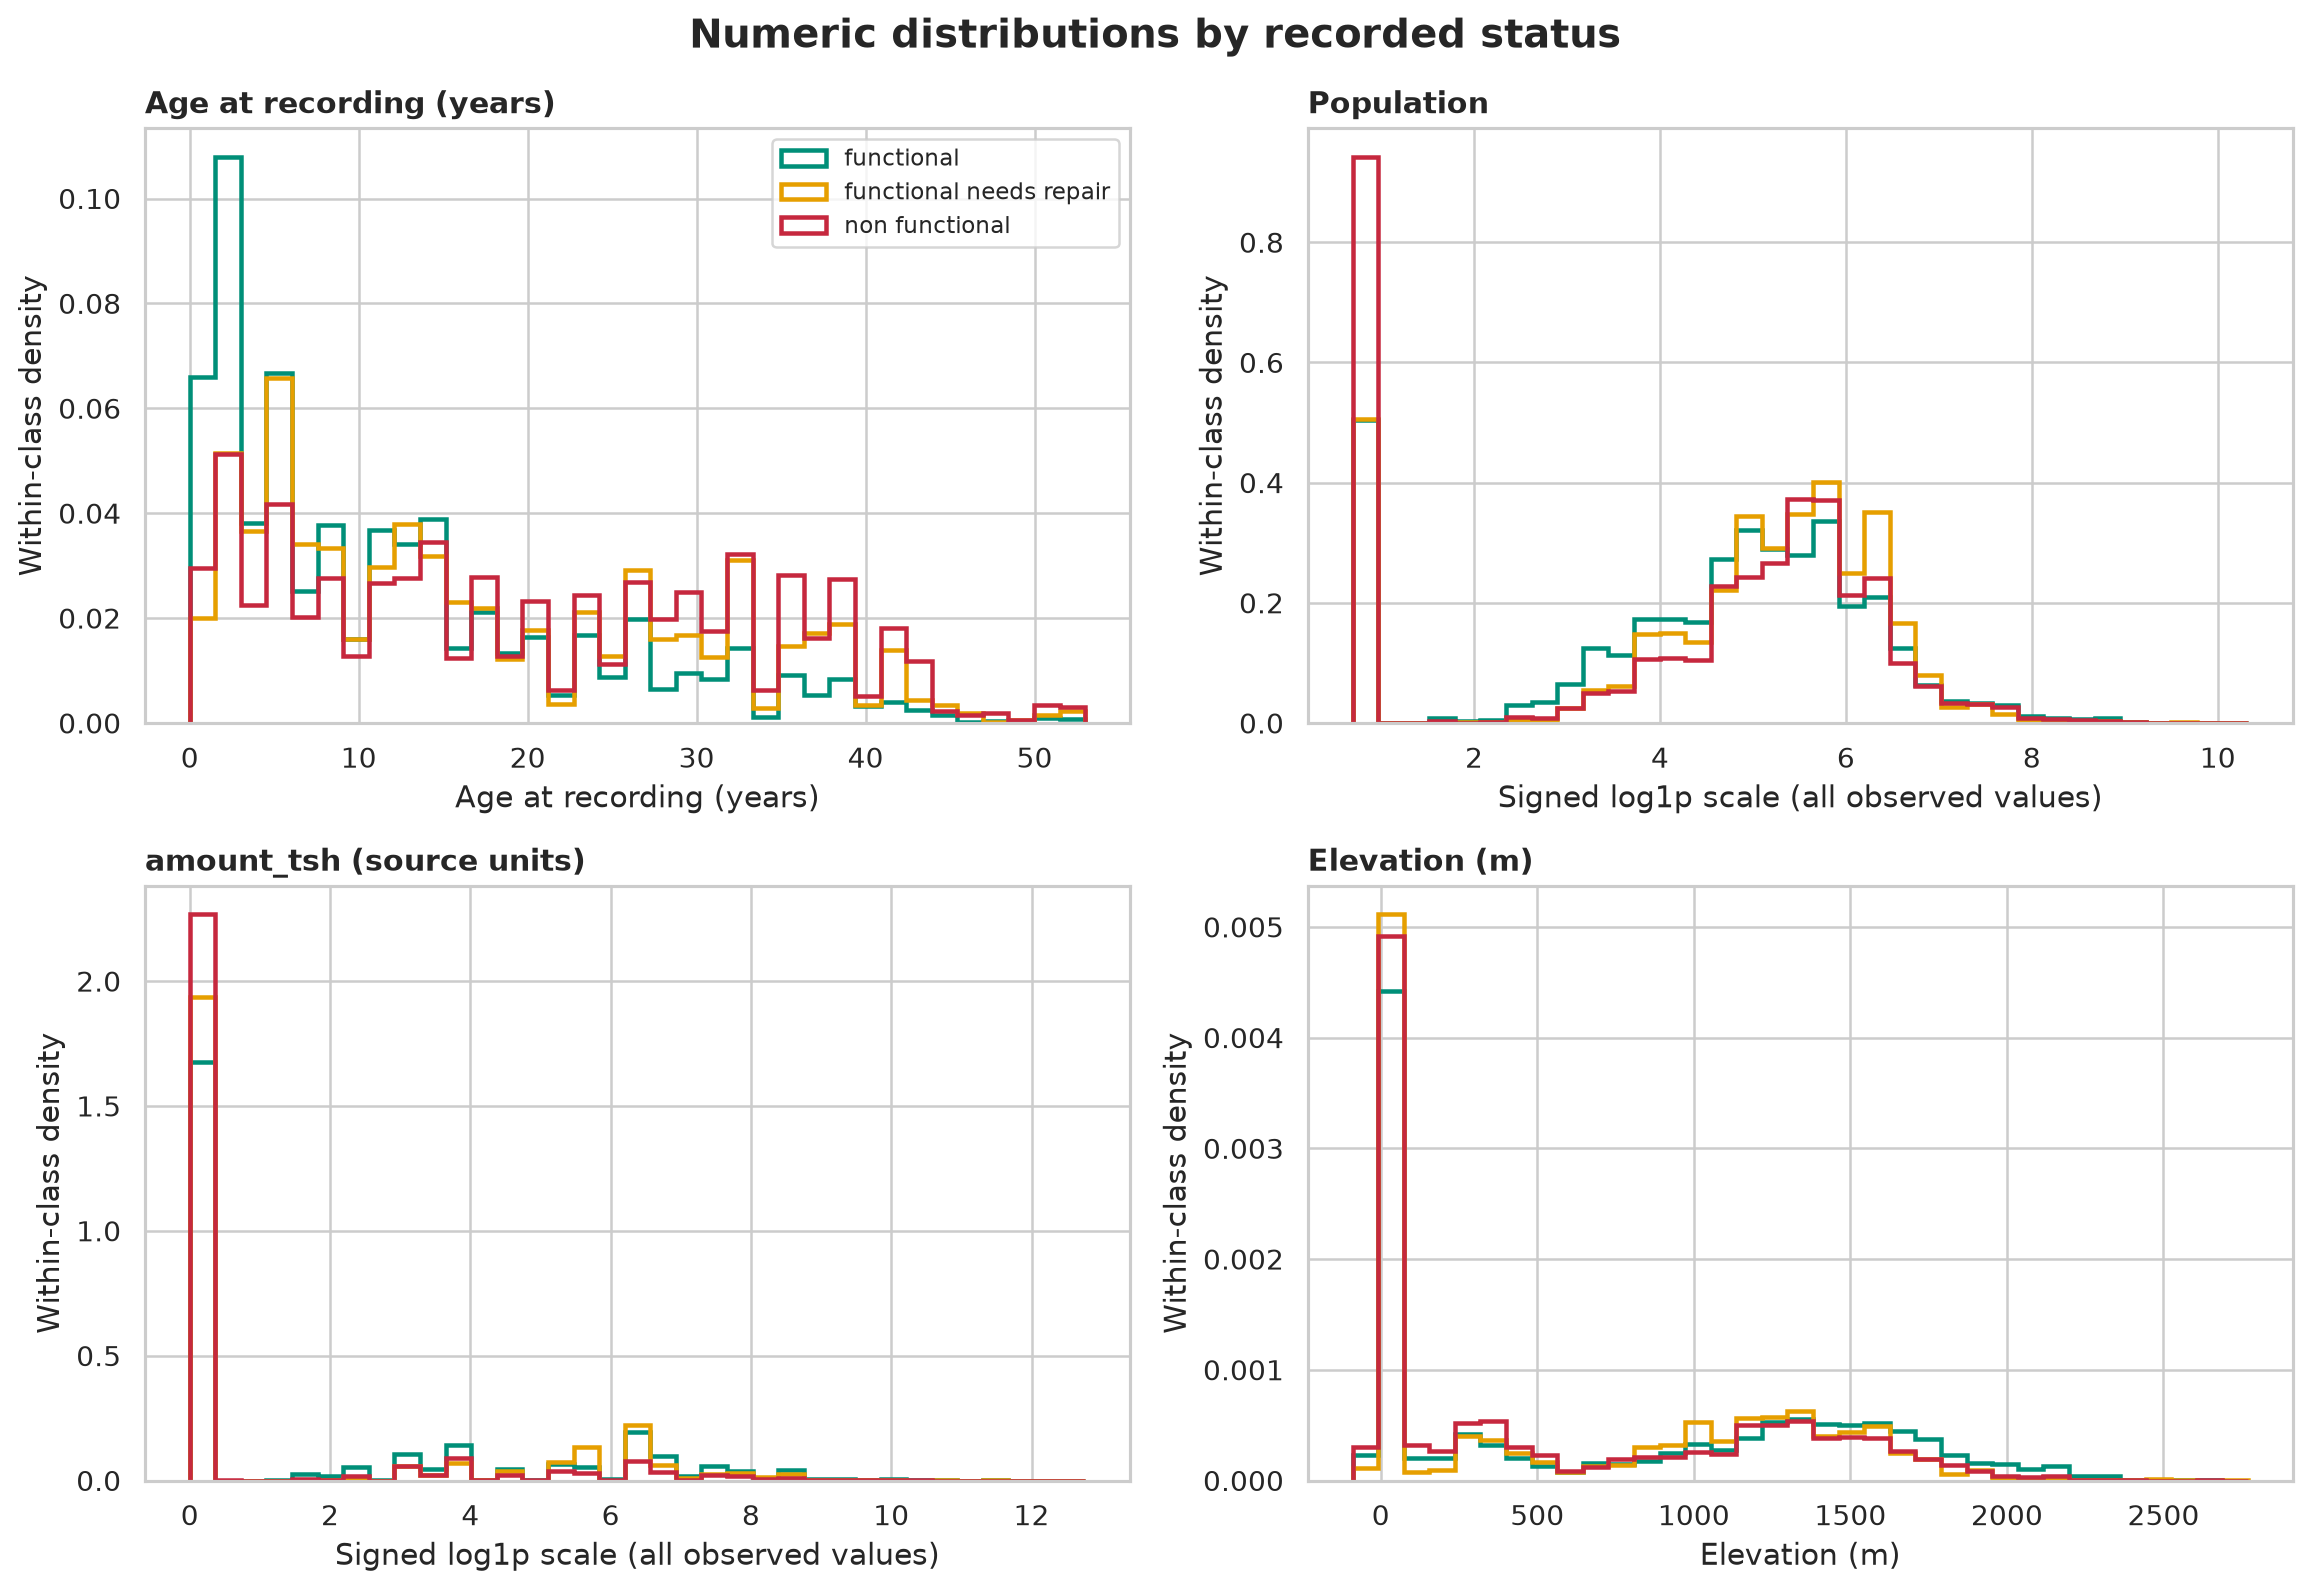

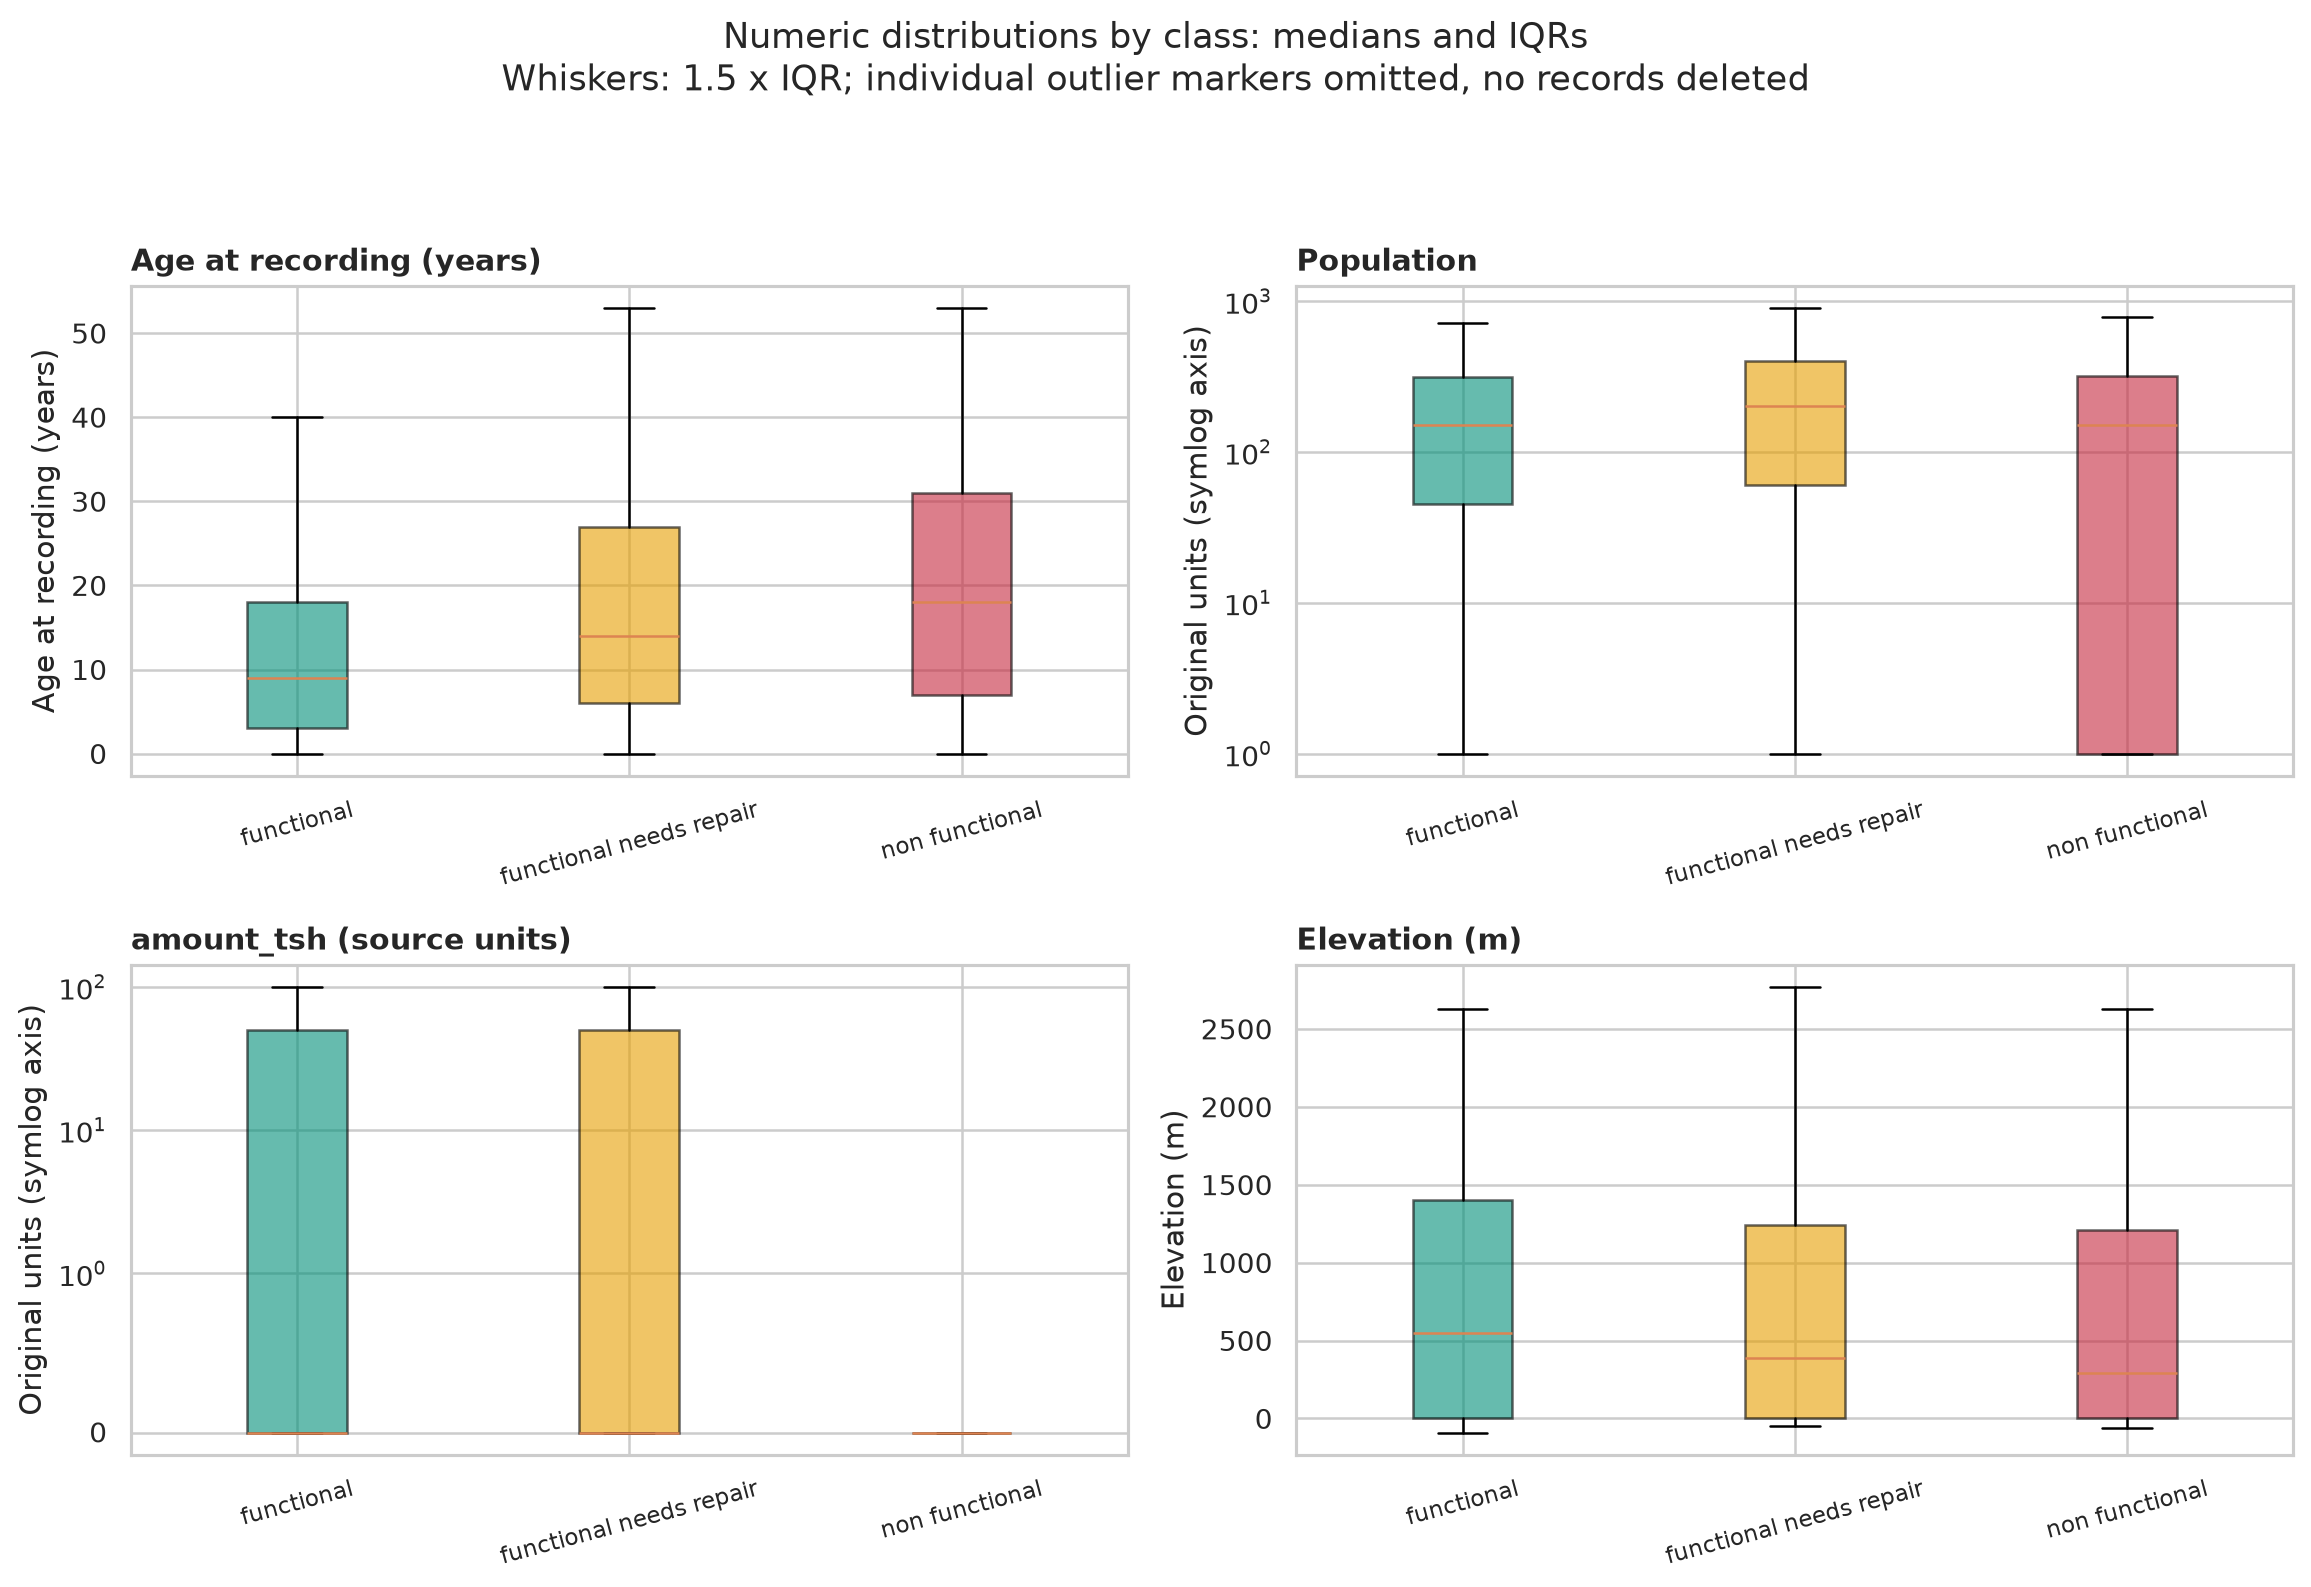

In [2]:
display(pd.DataFrame(results['numeric_summary']))
display(Image(filename=str(DEFAULT_OUTPUT / 'numeric_distributions.png')))
display(Image(filename=str(DEFAULT_OUTPUT / 'numeric_boxplots.png')))

## Correlation and elevation-zero sensitivity

Spearman correlations describe monotonic relationships. Pearson coefficients are also saved in the aggregate JSON. Pairwise valid counts accompany the matrices. The second panel excludes zero elevation only for sensitivity; it does not change the shared cleaner or establish that every zero is missing.

base


,pump_age,population,amount_tsh,gps_height
pump_age,1.000,-0.018,-0.085,0.033
population,-0.018,1.000,0.019,-0.066
amount_tsh,-0.085,0.019,1.000,0.342
gps_height,0.033,-0.066,0.342,1.000


,pump_age,population,amount_tsh,gps_height
pump_age,38682,37335,38682,38682
population,37335,38019,38019,38019
amount_tsh,38682,38019,59400,59400
gps_height,38682,38019,59400,59400


elevation_sensitivity


,pump_age,population,amount_tsh,gps_height
pump_age,1.000,-0.018,-0.085,0.037
population,-0.018,1.000,0.019,-0.063
amount_tsh,-0.085,0.019,1.000,0.022
gps_height,0.037,-0.063,0.022,1.000


,pump_age,population,amount_tsh,gps_height
pump_age,38682,37335,38682,37919
population,37335,38019,38019,37249
amount_tsh,38682,38019,59400,38962
gps_height,37919,37249,38962,38962


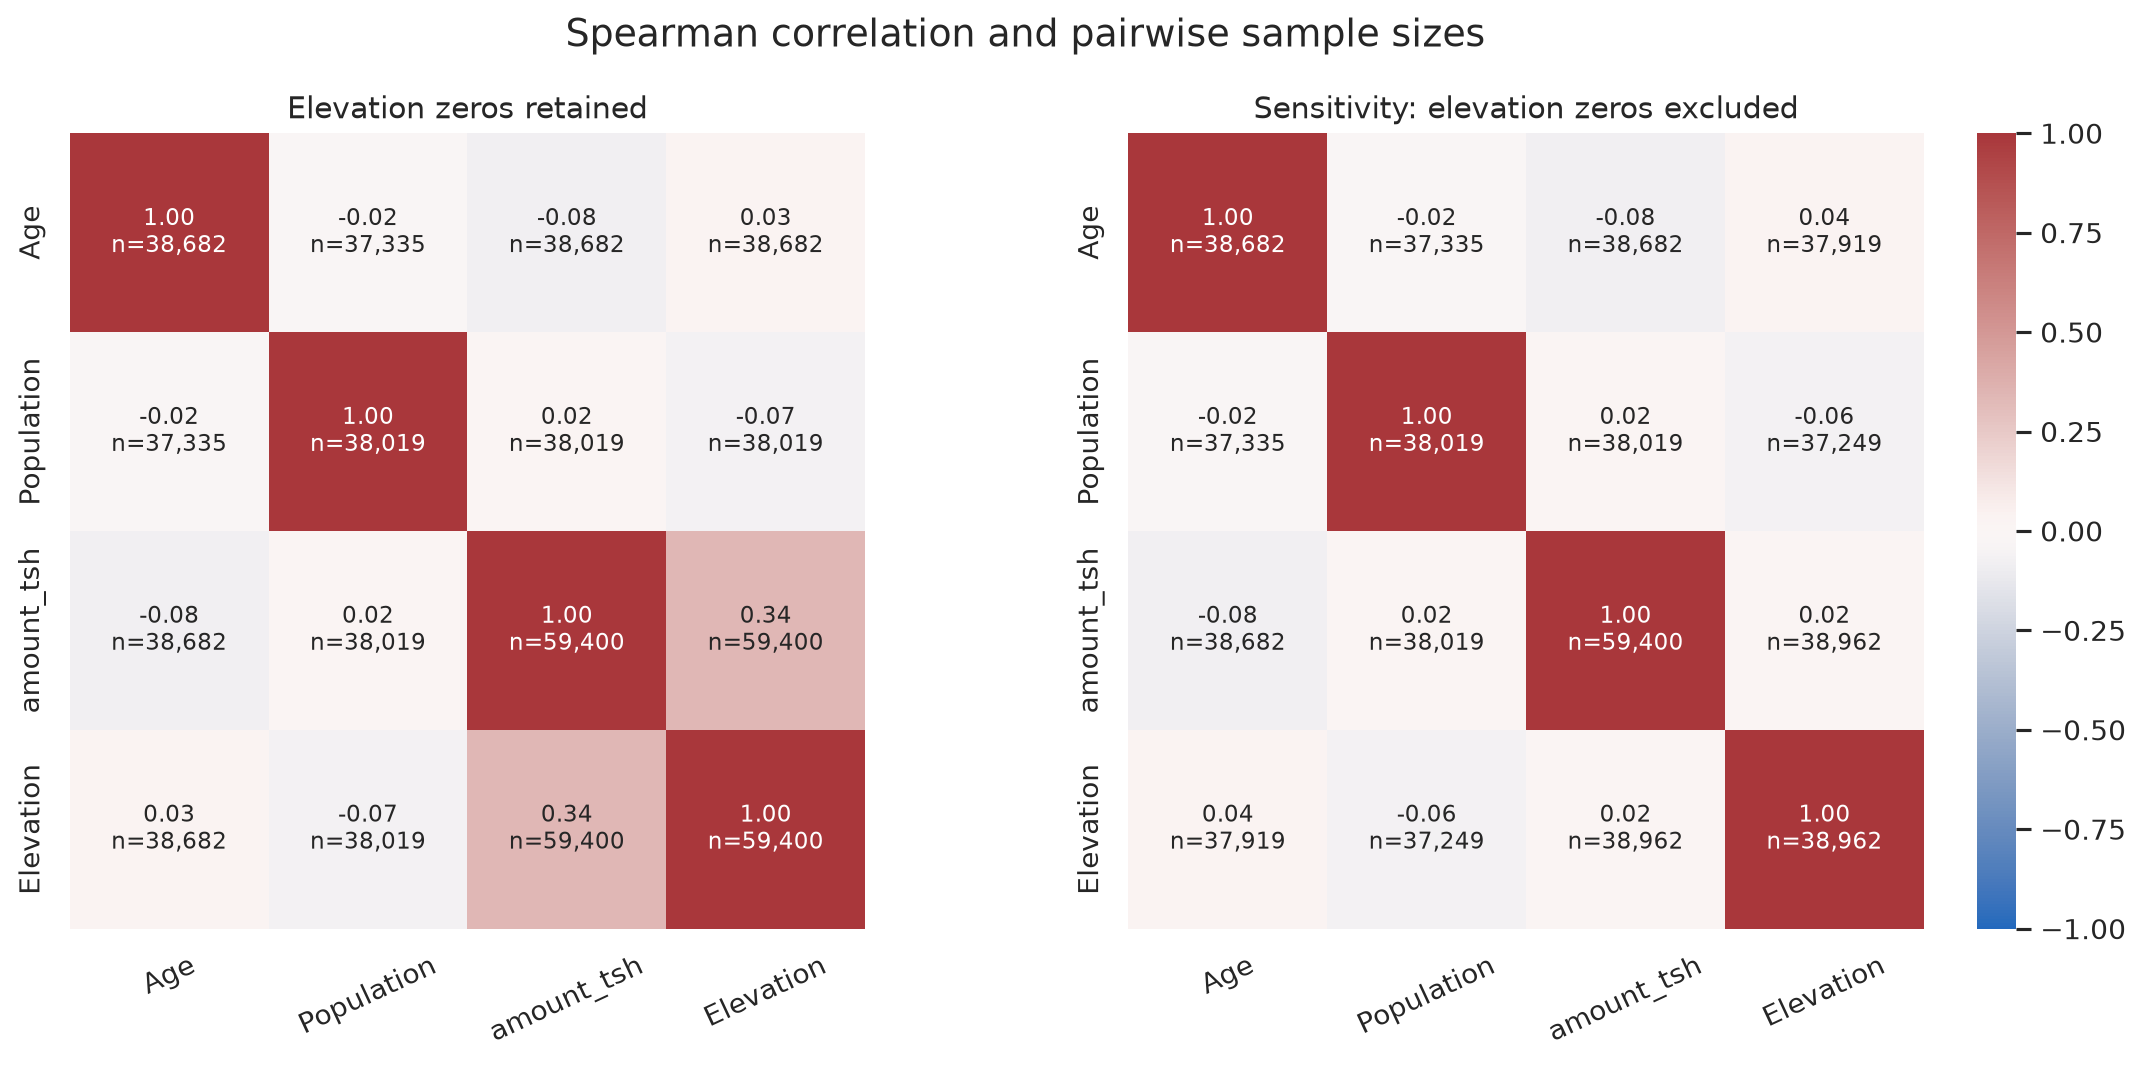

In [3]:
features = results['correlations']['features']
for scenario in ['base', 'elevation_sensitivity']:
    print(scenario)
    display(pd.DataFrame(results['correlations'][scenario]['spearman'],
                         index=features, columns=features).round(3))
    display(pd.DataFrame(results['correlations'][scenario]['pairwise_n'],
                         index=features, columns=features))
display(Image(filename=str(DEFAULT_OUTPUT / 'numeric_spearman_heatmaps.png')))

## Missingness and coverage

Each missing percentage uses its class or region's full denominator. For construction year and population, unknown zeros count as missing after shared cleaning. For the other fields, these are actual nulls; textual tokens such as 'unknown' and '0' remain separate categories. The age-availability table compares target composition among included and excluded observations.

group,functional,functional needs repair,non functional
feature,,,
construction_year,32.72,41.44,36.65
funder,6.14,10.12,5.34
installer,6.20,10.19,5.32
permit,5.19,6.95,4.75
population,34.95,41.12,36.51
public_meeting,5.20,3.61,6.57
scheme_management,5.81,5.17,7.80
scheme_name,46.19,47.12,52.03


,availability,status,n,status_n,status_pct
0,Invalid year/date/age,functional,9,4,44.444444
1,Invalid year/date/age,functional needs repair,9,0,0.000000
2,Invalid year/date/age,non functional,9,5,55.555556
3,Unknown construction year,functional,20709,10555,50.968178
4,Unknown construction year,functional needs repair,20709,1789,8.638756
5,Unknown construction year,non functional,20709,8365,40.393066
6,Usable age,functional,38682,21700,56.098444
7,Usable age,functional needs repair,38682,2528,6.535339
8,Usable age,non functional,38682,14454,37.366217


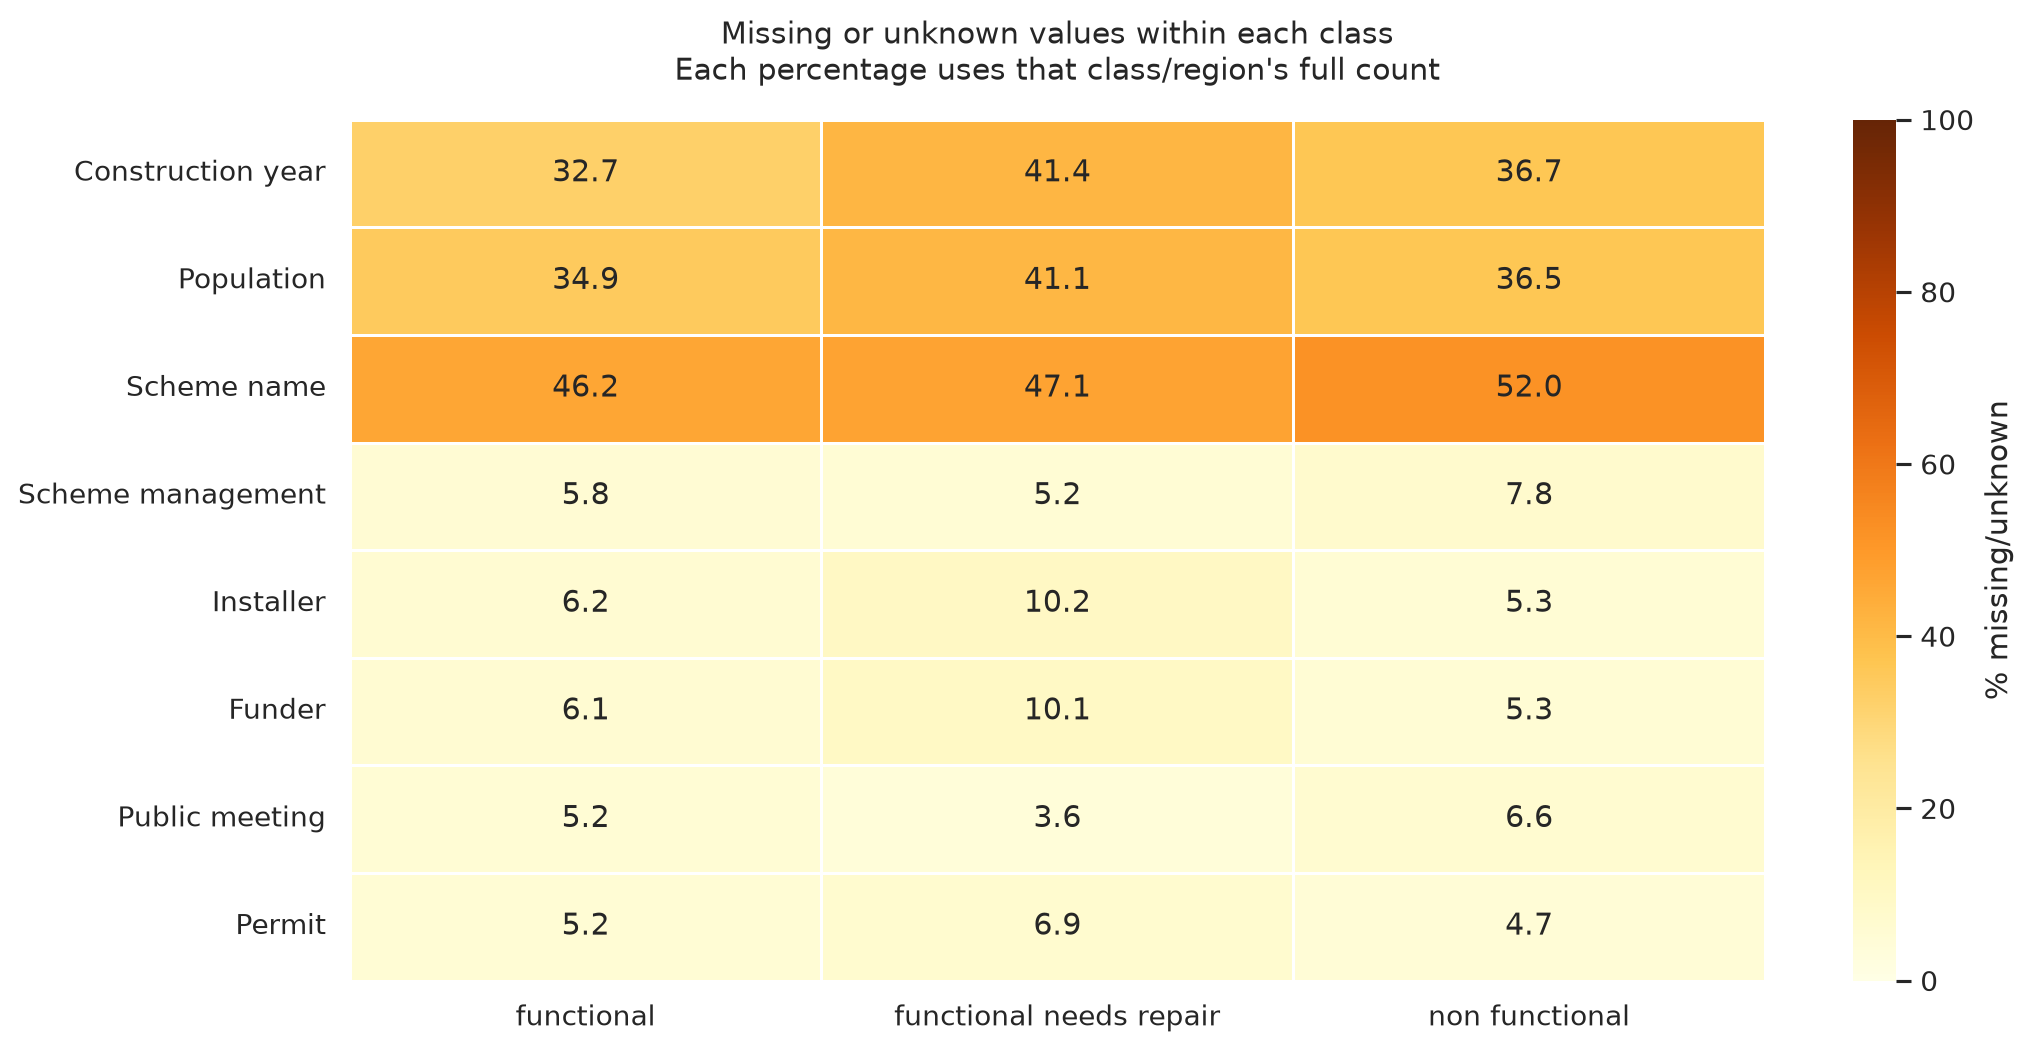

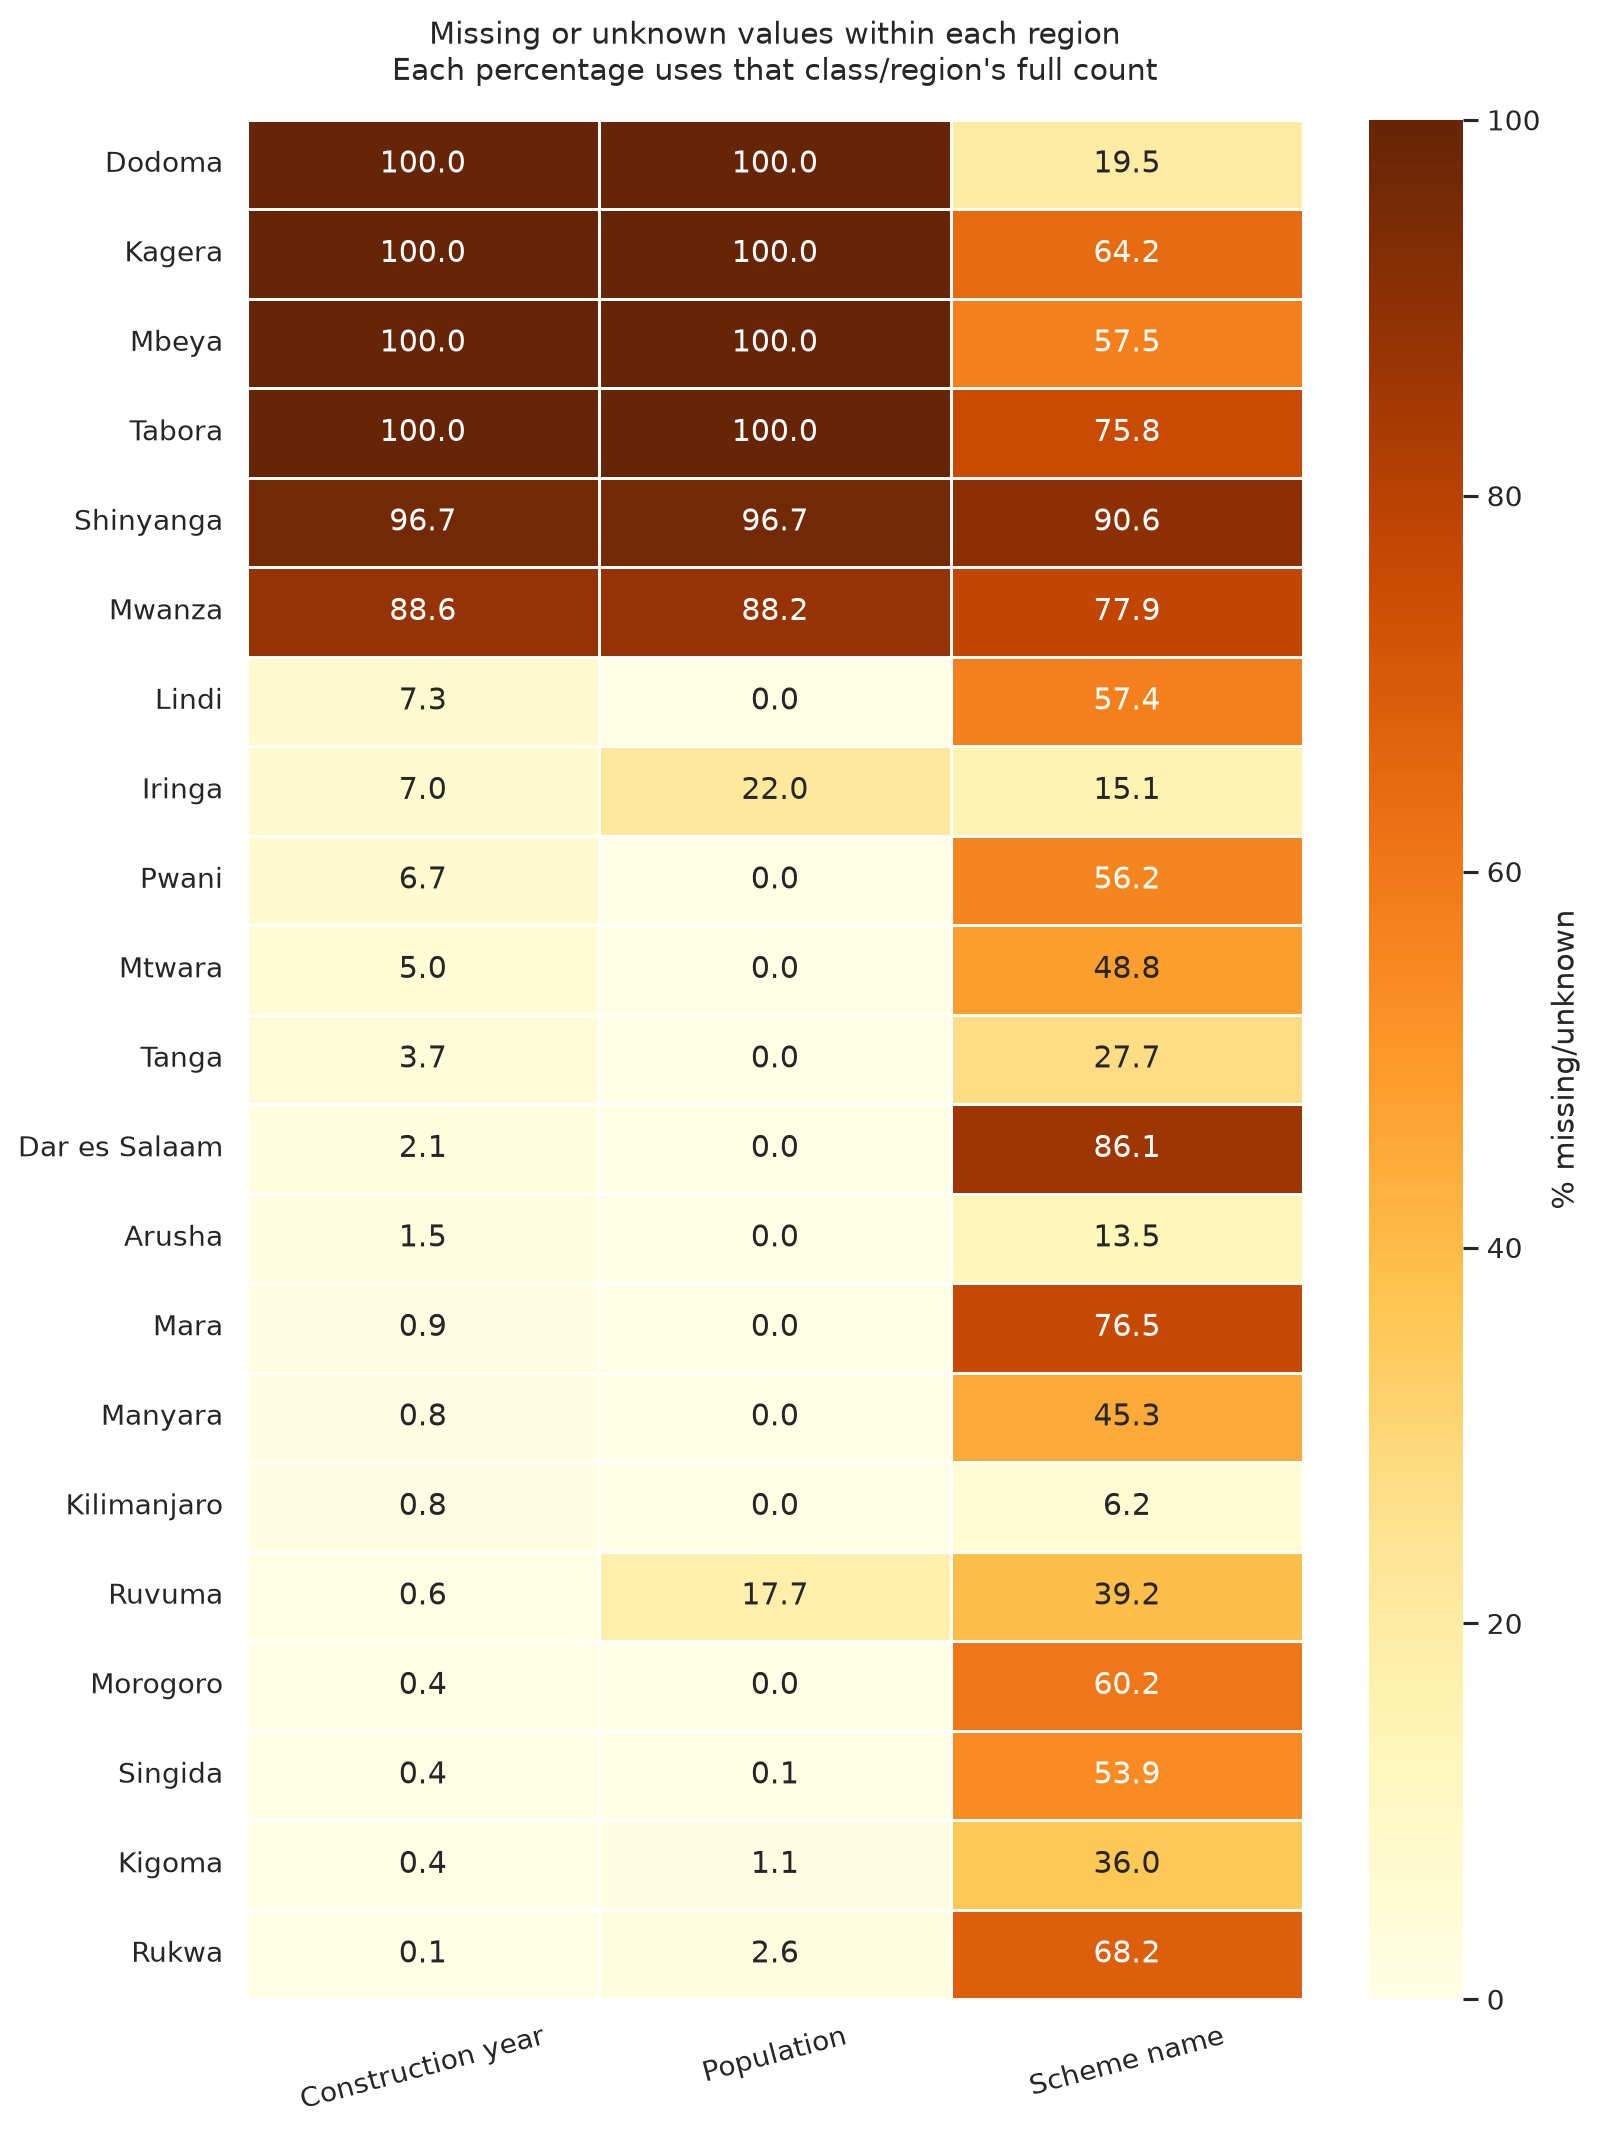

In [4]:
display(pd.DataFrame(results['missingness_by_status']).pivot(
    index='feature', columns='group', values='missing_pct').round(2))
display(pd.DataFrame(results['age_availability']))
display(Image(filename=str(DEFAULT_OUTPUT / 'missingness_by_status.png')))
display(Image(filename=str(DEFAULT_OUTPUT / 'missingness_by_region.png')))

## Age within region and extraction class

Cells with fewer than 30 observations show only their counts. Regions with no usable ages remain visible. Extreme-age comparisons require at least 30 observations in both the 0-5 and 31+ groups within a stratum. All three target-class counts and shares are saved.

Direct standardization applies the same stratum weights to both age groups, using each eligible stratum's share of the combined youngest and oldest records. The pooled comparison uses exactly those same eligible strata. Region and extraction class are considered separately. This does not jointly adjust for other variables or identify a causal effect.

region


,region,young_n,young_functional,young_pct,old_n,old_functional,old_pct,eligible,young_minus_old_pp
0,Arusha,874,728,83.30,450,226,50.22,True,33.07
1,Dar es Salaam,319,270,84.64,77,4,5.19,True,79.44
2,Dodoma,0,0,NaN,0,0,NaN,False,NaN
3,Iringa,1844,1589,86.17,669,403,60.24,True,25.93
4,Kagera,0,0,NaN,0,0,NaN,False,NaN
5,Kigoma,657,335,50.99,289,100,34.60,True,16.39
6,Kilimanjaro,1437,1061,73.83,1104,283,25.63,True,48.20
7,Lindi,383,208,54.31,382,38,9.95,True,44.36
8,Manyara,579,407,70.29,115,47,40.87,True,29.42
9,Mara,597,425,71.19,222,35,15.77,True,55.42


eligible_strata              16.000000
common_n                  17923.000000
young_n                   11587.000000
young_pooled_pct             71.493916
young_standardized_pct       70.099543
old_n                      6336.000000
old_pooled_pct               31.423611
old_standardized_pct         32.859924
pooled_gap_pp                40.070304
standardized_gap_pp          37.239619
dtype: float64

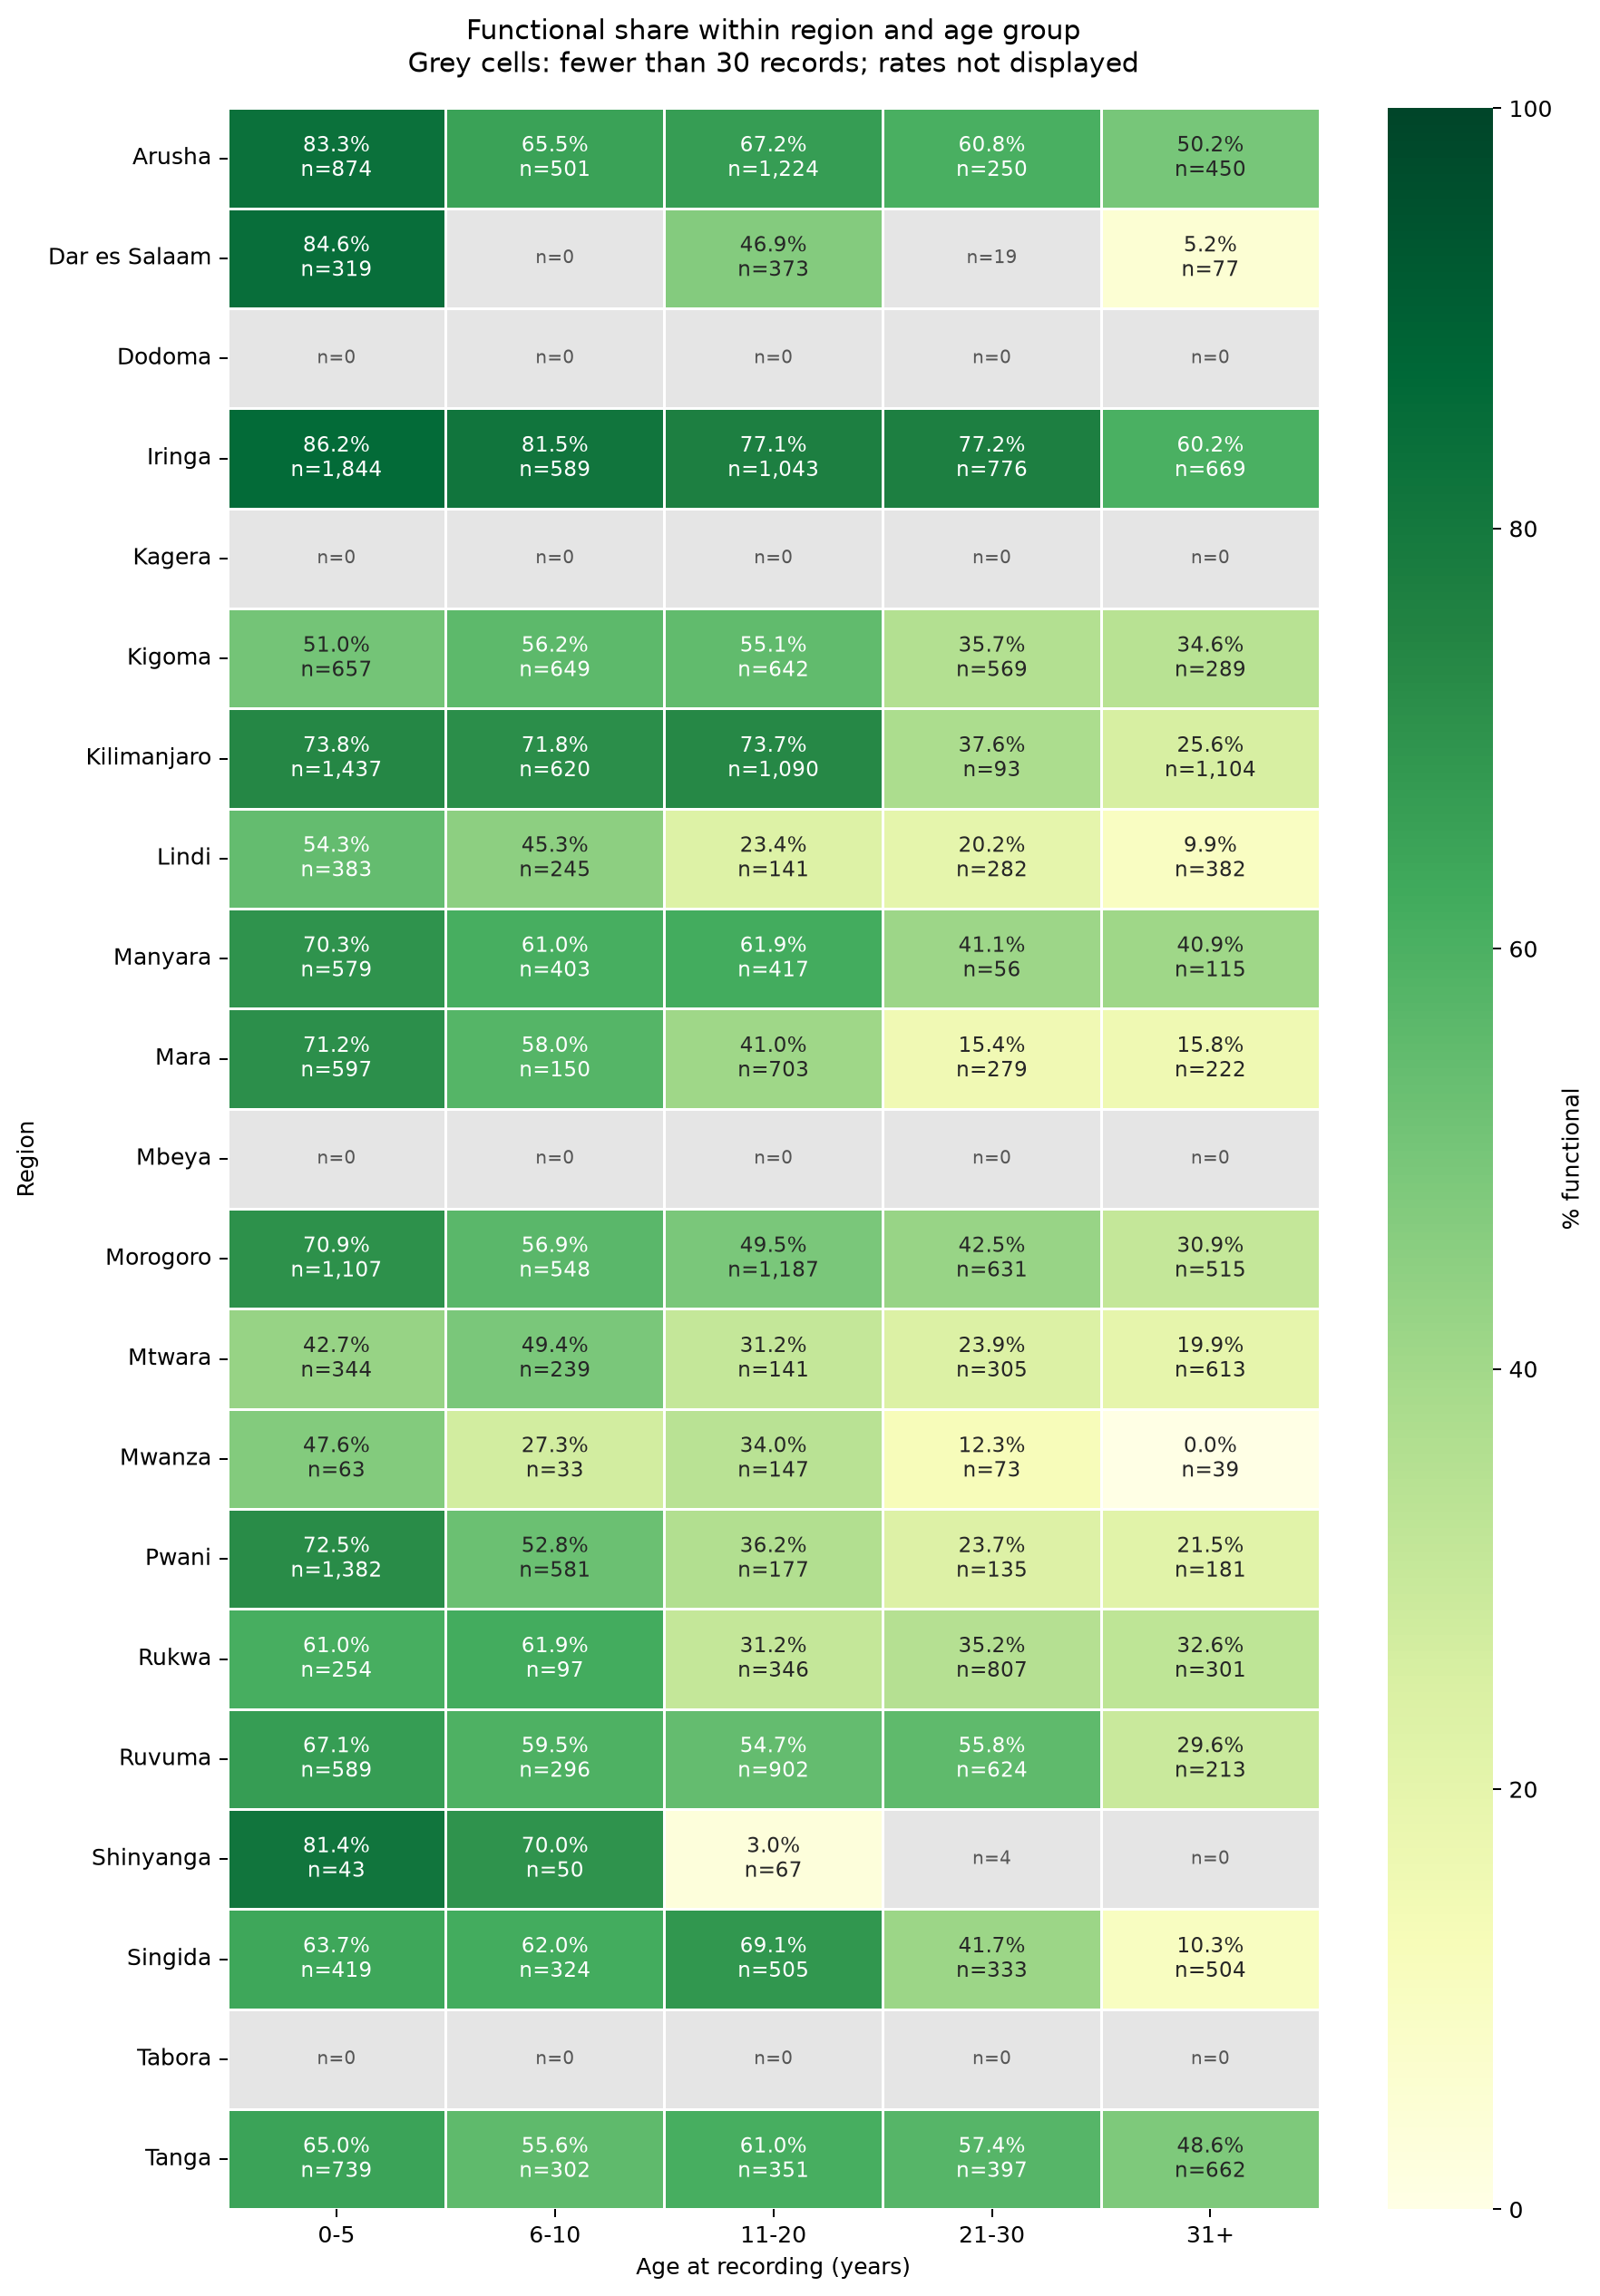

extraction_type_class


,extraction_type_class,young_n,young_functional,young_pct,old_n,old_functional,old_pct,eligible,young_minus_old_pp
0,gravity,5647,4375,77.47,3892,1525,39.18,True,38.29
1,handpump,2418,1674,69.23,309,178,57.61,True,11.63
2,motorpump,537,333,62.01,608,66,10.86,True,51.16
3,other,711,240,33.76,692,43,6.21,True,27.54
4,rope pump,259,216,83.40,2,1,50.00,False,33.40
5,submersible,2039,1472,72.19,817,175,21.42,True,50.77
6,wind-powered,19,9,47.37,16,3,18.75,False,28.62


eligible_strata               5.000000
common_n                  17670.000000
young_n                   11352.000000
young_pooled_pct             71.300211
young_standardized_pct       70.875303
old_n                      6318.000000
old_pooled_pct               31.449826
old_standardized_pct         34.701627
pooled_gap_pp                39.850386
standardized_gap_pp          36.173676
dtype: float64

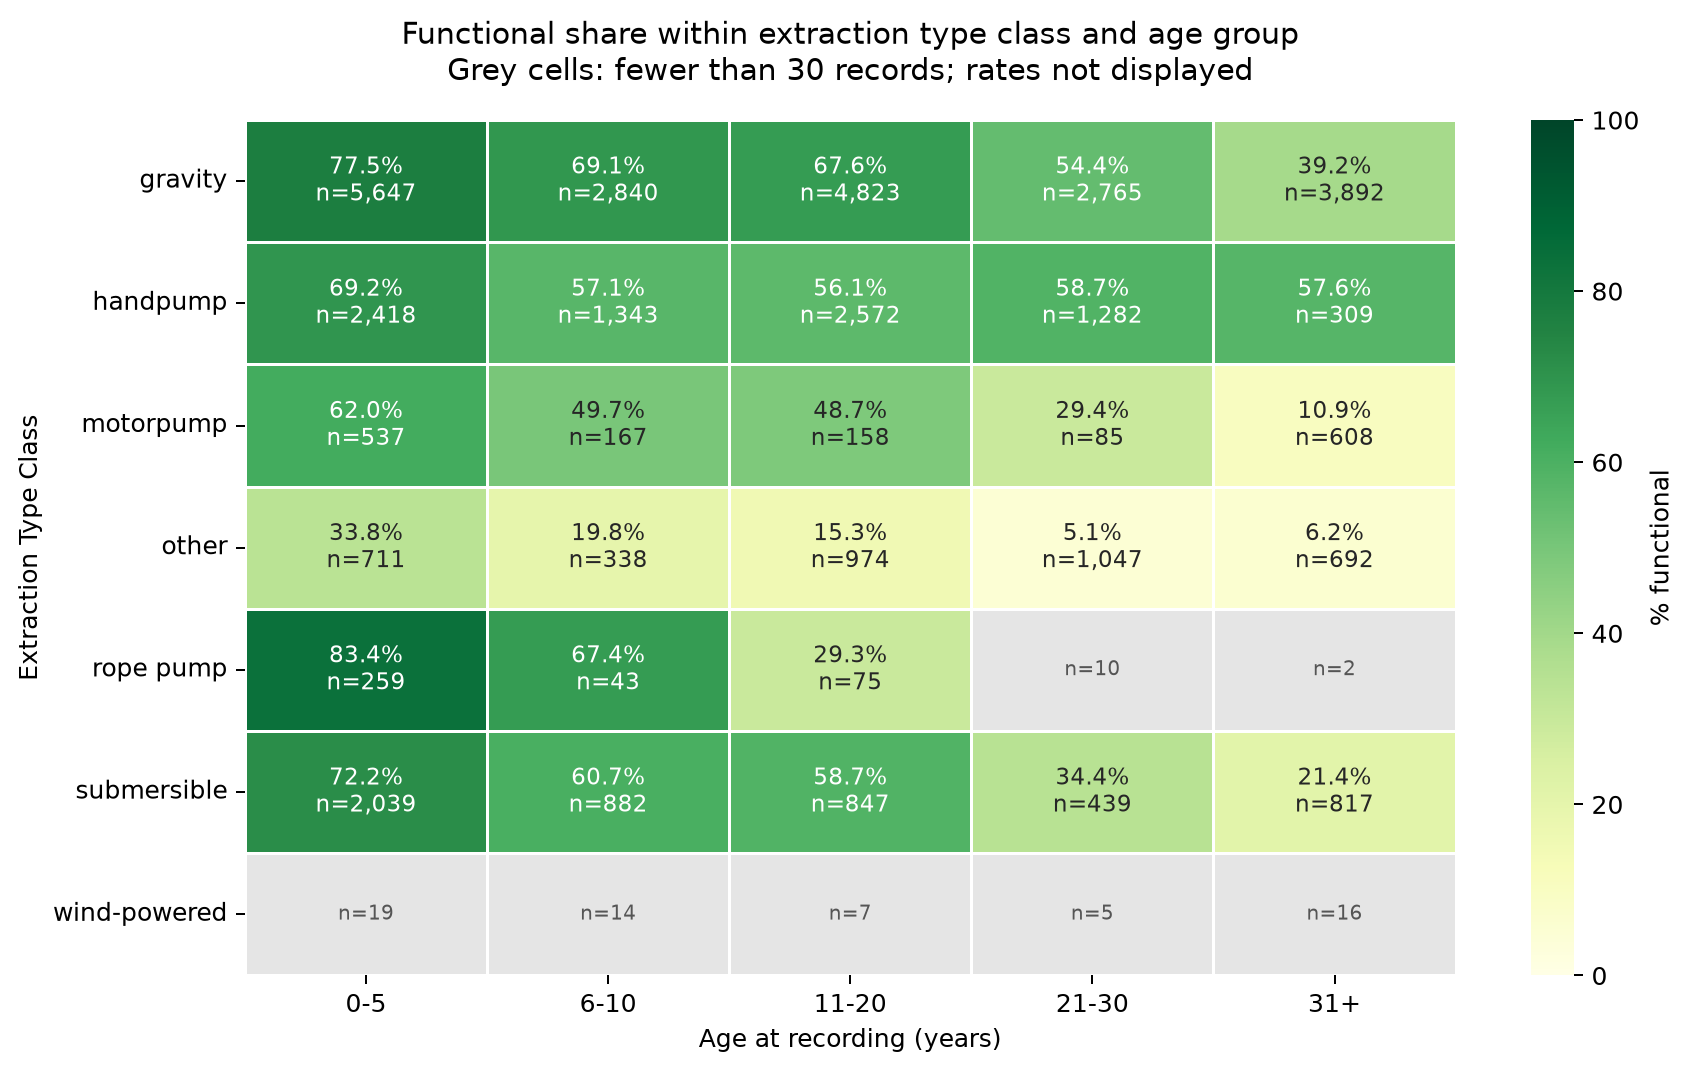

In [5]:
for stratum in ['region', 'extraction_type_class']:
    print(stratum)
    display(pd.DataFrame(results[stratum]['contrasts']).round(2))
    display(pd.Series(results[stratum]['standardized']))
    display(Image(filename=str(DEFAULT_OUTPUT / f'age_by_{stratum}.png')))

## Reproducibility and interpretation

The JSON contains input-file SHA-256 hashes, aggregate counts, numeric summaries, both correlation methods, pairwise sample sizes, missingness tables, age-cell counts and standardization results. No individual waterpoint records are exported.

Duplicate observations remain in the analysis under the existing audit policy. These cross-sectional comparisons describe associations. Missing ages, recording practices, cohort differences, geography and unmeasured factors limit interpretation. Time-series ACF/PACF and spatial autocorrelation are outside these three analyses.

In [6]:
summary = json.loads((DEFAULT_OUTPUT / 'summary.json').read_text())
assert summary['counts'] == results['counts']
assert sum(row['n'] for row in results['region']['age_rates']) == results['counts']['usable_age']
print('Aggregate outputs:', DEFAULT_OUTPUT)
print('Input hashes:', summary['inputs'])

Aggregate outputs: /home/whitemerald/redi-school_repo/data-circle/projects/water_pumps/team-WTM/reports/additional_eda
Input hashes: {'Training_set_values.csv': 'd8ebe40f49fe749a851c8ea28601115cd92442f7b20025fbc33881595ae75f5d', 'Training_set_labels.csv': 'ae9b4f893e8e89df3a2187d38cade75c61dfb1d1e156ecd7615fee14fdbe0a24'}
